# Desempenho estudantil e curso preparatório

## Objetivo
Investigar se estudantes que concluíram o curso preparatório apresentam nota média de matemática maior e proporção de aprovação maior do que estudantes que não fizeram o curso. Neste projeto, aprovação é definida como nota ≥ 60, uma definição operacional para esta análise.

**Perguntas:** (1) a média de matemática é maior no grupo `completed`? (2) a proporção com nota ≥ 60 é maior nesse grupo?

Os dados são observacionais: associações encontradas não demonstram que o curso causou as diferenças.


## 1. Bibliotecas e configurações

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

ALPHA = 0.05
NOTA_APROVACAO = 60
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (9, 5), "axes.titlesize": 14, "axes.labelsize": 11})


## 2. Carregamento e inspeção

In [2]:
arquivo = Path("StudentsPerformance.csv")
if not arquivo.exists():
    raise FileNotFoundError(f"Coloque StudentsPerformance.csv na mesma pasta: {arquivo.resolve()}")
df_bruto = pd.read_csv(arquivo)
print(f"Dimensão: {df_bruto.shape[0]} linhas × {df_bruto.shape[1]} colunas")
display(df_bruto.head())
display(df_bruto.dtypes.to_frame("tipo"))


Dimensão: 1000 linhas × 8 colunas


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


,tipo
gender,str
race/ethnicity,str
parental level of education,str
lunch,str
test preparation course,str
math score,int64
reading score,int64
writing score,int64


## 3. Tratamento e validação

Padronizamos nomes de colunas, removemos espaços excedentes de textos e validamos ausências, categorias e limites das notas. O fluxo registra quantas linhas saem da análise caso novas versões tenham dados ausentes.

In [3]:
df = df_bruto.copy()
df.columns = df.columns.str.strip().str.lower()
for coluna in df.select_dtypes(include="object").columns:
    df[coluna] = df[coluna].str.strip()
notas = ["math score", "reading score", "writing score"]
obrigatorias = set(notas + ["test preparation course", "gender"])
if obrigatorias - set(df.columns):
    raise ValueError(f"Colunas ausentes: {sorted(obrigatorias - set(df.columns))}")
for coluna in notas:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")
print("Ausências por coluna:"); display(df.isna().sum().to_frame("ausências"))
if not df["test preparation course"].dropna().isin(["none", "completed"]).all():
    raise ValueError("Categoria inesperada em test preparation course")
for coluna in notas:
    if not df[coluna].dropna().between(0, 100).all():
        raise ValueError(f"Notas fora do intervalo 0–100 em {coluna}")
n_antes = len(df)
df = df.dropna(subset=notas + ["test preparation course"]).copy()
print(f"Registros removidos: {n_antes-len(df)} | registros válidos: {len(df)}")


Ausências por coluna:


C:\Users\Magora\AppData\Local\Temp\ipykernel_25196\3258748227.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for coluna in df.select_dtypes(include="object").columns:


,ausências
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


Registros removidos: 0 | registros válidos: 1000


## 4. Estatística descritiva

In [4]:
ordem = ["none", "completed"]
rotulos = {"none": "Sem curso", "completed": "Curso concluído"}
resumo = df.groupby("test preparation course", observed=True)[notas].agg(["count", "mean", "median", "std"]).reindex(ordem)
display(resumo.round(2))


math score                      reading score         \
                             count   mean median    std         count   mean   
test preparation course                                                        
none                           642  64.08   64.0  15.19           642  66.53   
completed                      358  69.70   69.0  14.44           358  73.89   

                                      writing score                       
                        median    std         count   mean median    std  
test preparation course                                                   
none                      67.0  14.46           642  64.50   65.0  15.00  
completed                 75.0  13.64           358  74.42   76.0  13.38

### Distribuição das notas por disciplina

Painéis separados com uma escala comparável para matemática, leitura e escrita.

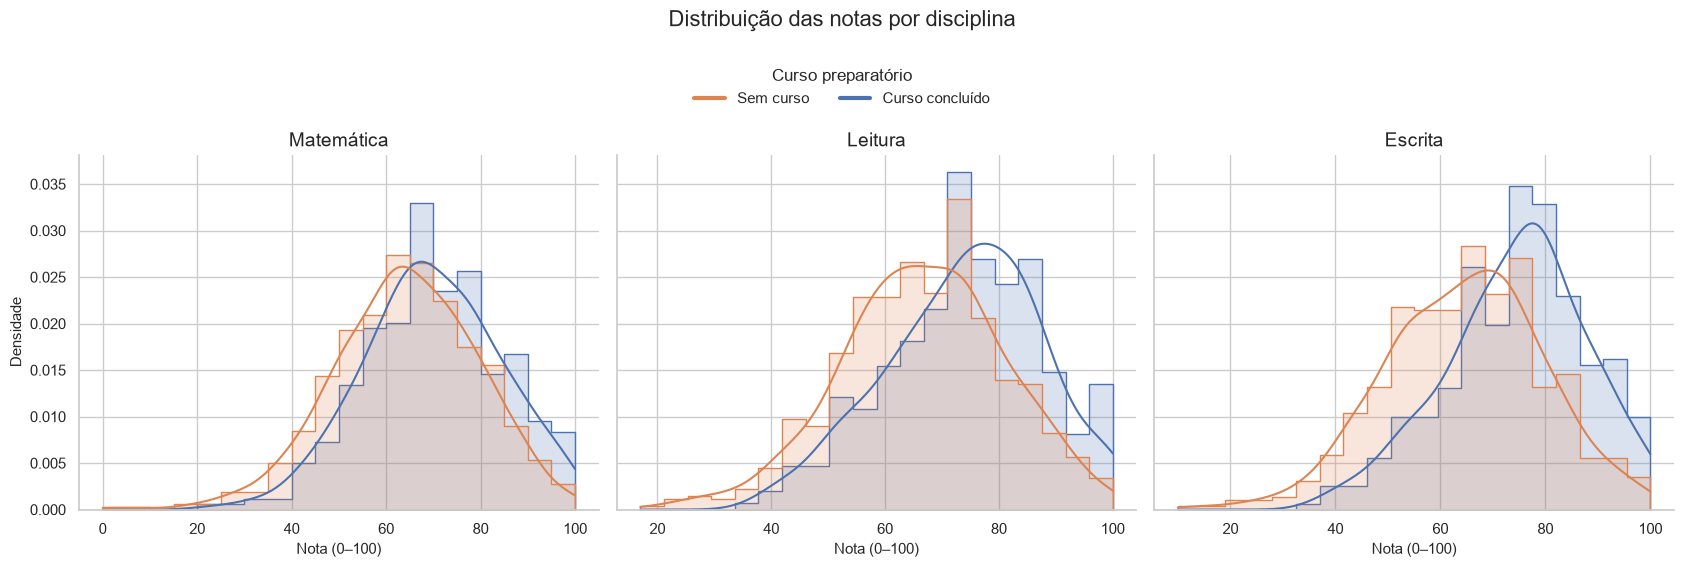

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
cores = {"none": "#dd8452", "completed": "#4c72b0"}  # paleta padrão Seaborn

for ax, coluna, titulo in zip(axes, notas, ["Matemática", "Leitura", "Escrita"]):
    sns.histplot(data=df, x=coluna, hue="test preparation course", hue_order=ordem, palette=cores,
                 bins=20, stat="density", common_norm=False, element="step", fill=True, alpha=.2, kde=True, ax=ax)
    ax.set(title=titulo, xlabel="Nota (0–100)", ylabel="Densidade")
    if ax.legend_: ax.legend_.remove()

fig.legend(handles=[plt.Line2D([], [], color=cores[g], lw=3, label=rotulos[g]) for g in ordem],
           title="Curso preparatório", loc="upper center", ncol=2, bbox_to_anchor=(.5, 1.04), frameon=False)
fig.suptitle("Distribuição das notas por disciplina", y=1.13, fontsize=16)
sns.despine(); plt.tight_layout(); plt.show()

### Comparação da dispersão

C:\Users\Magora\AppData\Local\Temp\ipykernel_25196\1340424962.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([rotulos[x] for x in ordem])
C:\Users\Magora\AppData\Local\Temp\ipykernel_25196\1340424962.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([rotulos[x] for x in ordem])
C:\Users\Magora\AppData\Local\Temp\ipykernel_25196\1340424962.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([rotulos[x] for x in ordem])


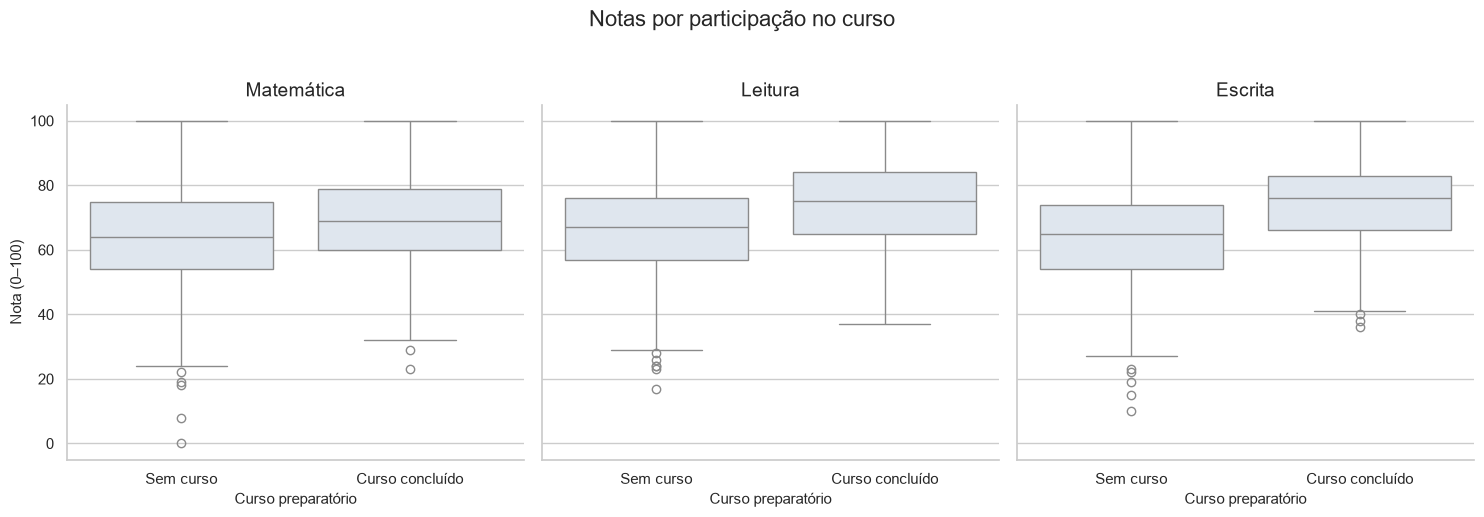

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, coluna, titulo in zip(axes, notas, ["Matemática", "Leitura", "Escrita"]):
    sns.boxplot(data=df, x="test preparation course", y=coluna, order=ordem, ax=ax, color="#dce6f1")
    ax.set(title=titulo, xlabel="Curso preparatório", ylabel="Nota (0–100)")
    ax.set_xticklabels([rotulos[x] for x in ordem])
fig.suptitle("Notas por participação no curso", y=1.03, fontsize=16)
sns.despine(); plt.tight_layout(); plt.show()


## 5. Teste de hipótese: média de matemática
Sejam $\mu_C$ e $\mu_N$ as médias de quem concluiu e não fez o curso.

- $H_0: \mu_C \leq \mu_N$
- $H_1: \mu_C > \mu_N$
- Teste unilateral; $\alpha=0{,}05$.

Usamos o teste t de Welch para amostras independentes, sem presumir variâncias iguais. Independência e representatividade dependem do desenho da coleta e não são garantidas pelo teste.

In [7]:
grupo_curso = df.loc[df["test preparation course"].eq("completed"), "math score"]
grupo_sem = df.loc[df["test preparation course"].eq("none"), "math score"]
resultado_media = stats.ttest_ind(grupo_curso, grupo_sem, equal_var=False, alternative="greater")
diferenca_media = grupo_curso.mean() - grupo_sem.mean()
se = np.sqrt(grupo_curso.var(ddof=1)/len(grupo_curso) + grupo_sem.var(ddof=1)/len(grupo_sem))
limites = stats.t.interval(.95, df=resultado_media.df, loc=diferenca_media, scale=se)
print(f"Média com curso: {grupo_curso.mean():.2f} (n={len(grupo_curso)})")
print(f"Média sem curso: {grupo_sem.mean():.2f} (n={len(grupo_sem)})")
print(f"Diferença (com − sem): {diferenca_media:.2f}; IC 95%: [{limites[0]:.2f}, {limites[1]:.2f}]")
print(f"t({resultado_media.df:.1f})={resultado_media.statistic:.3f}; p unilateral={resultado_media.pvalue:.4g}")
print("Rejeitamos H₀." if resultado_media.pvalue < ALPHA else "Não rejeitamos H₀: evidência insuficiente para afirmar média maior.")


Média com curso: 69.70 (n=358)
Média sem curso: 64.08 (n=642)
Diferença (com − sem): 5.62; IC 95%: [3.71, 7.52]
t(770.1)=5.787; p unilateral=5.213e-09
Rejeitamos H₀.


## 6. Teste de hipótese: proporção de aprovação
Aprovação é definida como nota de matemática ≥ 60. Seja $p_C$ a proporção de aprovados no grupo que concluiu o curso e $p_N$ a do grupo sem curso.

- $H_0: p_C \leq p_N$
- $H_1: p_C > p_N$
- Teste unilateral para duas proporções; $\alpha=0{,}05$.

Aqui comparamos a variável binária aprovado/reprovado, não as médias de notas.

In [13]:
aprovado = df["math score"] >= NOTA_APROVACAO
grupo_com_curso = df["test preparation course"].eq("completed")
grupo_sem_curso = df["test preparation course"].eq("none")
sucessos = [int((aprovado & grupo_com_curso).sum()), int((aprovado & grupo_sem_curso).sum())]
tamanhos = [int(grupo_com_curso.sum()), int(grupo_sem_curso.sum())]
proporcoes = [sucessos[i] / tamanhos[i] for i in range(2)]
estatistica_z, p_valor = proportions_ztest(sucessos, tamanhos, alternative="larger")
diferenca_prop = proporcoes[0] - proporcoes[1]
se_prop = np.sqrt(proporcoes[0] * (1 - proporcoes[0]) / tamanhos[0] + proporcoes[1] * (1 - proporcoes[1]) / tamanhos[1])
print(f"Aprovados com curso: {sucessos[0]}/{tamanhos[0]} = {proporcoes[0]:.1%}")
print(f"Aprovados sem curso: {sucessos[1]}/{tamanhos[1]} = {proporcoes[1]:.1%}")
print(f"Diferença (com − sem): {diferenca_prop:.1%}; IC 95% aproximado: [{diferenca_prop - 1.96 * se_prop:.1%}, {diferenca_prop + 1.96 * se_prop:.1%}]")
print(f"z={estatistica_z:.3f}; p unilateral={p_valor:.4g}")
if p_valor < ALPHA:
    print("Rejeitamos H₀: há evidência de uma proporção maior no grupo com curso.")
else:
    print("Não rejeitamos H₀: evidência insuficiente para afirmar uma proporção maior no grupo com curso.")

Aprovados com curso: 271/358 = 75.7%
Aprovados sem curso: 406/642 = 63.2%
Diferença (com − sem): 12.5%; IC 95% aproximado: [6.7%, 18.3%]
z=4.039; p unilateral=2.684e-05
Rejeitamos H₀: há evidência de uma proporção maior no grupo com curso.


### Visualização das taxas de aprovação

C:\Users\Magora\AppData\Local\Temp\ipykernel_25196\3494064940.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([rotulos[x] for x in ordem]); sns.despine(); plt.tight_layout(); plt.show()


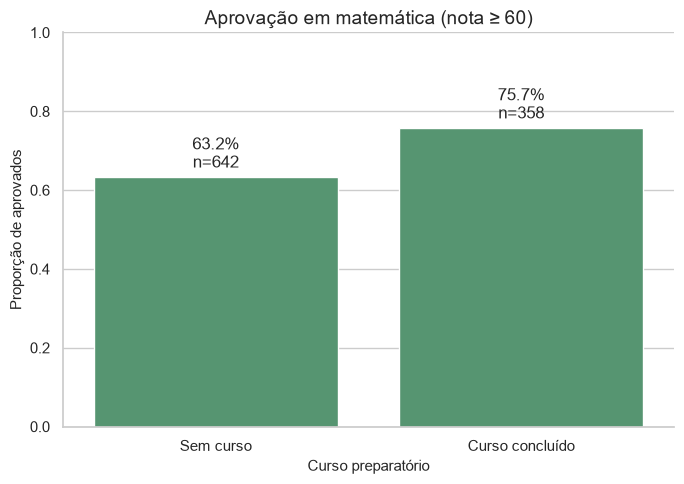

In [10]:
tab = (df.assign(aprovado=df["math score"] >= NOTA_APROVACAO)
    .groupby("test preparation course", observed=True)["aprovado"].agg(taxa="mean", n="size")
    .reindex(ordem).reset_index())
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=tab, x="test preparation course", y="taxa", order=ordem, ax=ax, color="#4c9f70")
for i, row in tab.iterrows(): ax.text(i, row.taxa+.025, f"{row.taxa:.1%}\nn={row.n}", ha="center")
ax.set(ylim=(0,1), title=f"Aprovação em matemática (nota ≥ {NOTA_APROVACAO})", xlabel="Curso preparatório", ylabel="Proporção de aprovados")
ax.set_xticklabels([rotulos[x] for x in ordem]); sns.despine(); plt.tight_layout(); plt.show()


## 7. Exploração complementar por gênero

O gráfico permite inspecionar notas médias de matemática por gênero e participação no curso. É uma exploração descritiva e não controla simultaneamente fatores de confusão.

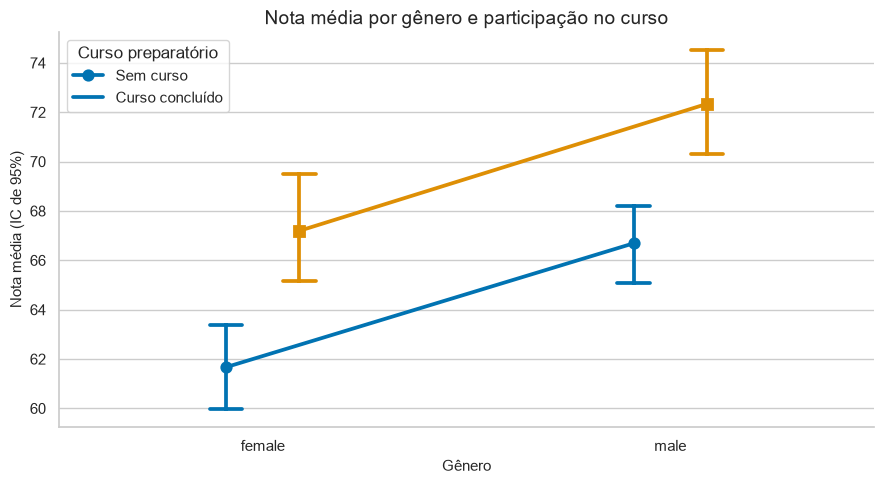

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.pointplot(data=df, x="gender", y="math score", hue="test preparation course", order=sorted(df.gender.unique()),
              hue_order=ordem, errorbar=("ci",95), dodge=.18, markers=["o","s"], capsize=.08, ax=ax)
ax.set(title="Nota média por gênero e participação no curso", xlabel="Gênero", ylabel="Nota média (IC de 95%)")
ax.legend(title="Curso preparatório", labels=[rotulos[x] for x in ordem]); sns.despine(); plt.tight_layout(); plt.show()


## 8. Conclusão e limitações
Compare as duas decisões com o nível de 5% e considere também o tamanho das diferenças e seus intervalos. Não rejeitar uma hipótese nula não prova igualdade. Como os dados são observacionais, não é possível atribuir causalidade ao curso sem um desenho apropriado. A amostra pode não representar todos os estudantes, e fatores como contexto socioeconômico ou escolaridade dos responsáveis podem influenciar as notas.